# 02 - Três métodos de seleção de atributos e votação

**Etapa 3** | Fluxo: passos 4 e 5

Três métodos independentes elegem os 10 melhores atributos cada um, sempre **ajustados só no treino**:

| Método | O que mede |
|---|---|
| `SelectKBest` com informação mútua | dependência estatística (inclui não linear) entre atributo e churn |
| Importância do Random Forest | redução média de impureza |
| RFE com Regressão Logística | eliminação recursiva de atributos pouco úteis a um modelo linear |

**Regra de votação (fixada no `config.yaml` antes de rodar):** eleito = aparece no top-k de **>= 2 dos 3** métodos.
Piso de 6 e teto de 14 atributos; se houver corte ou complemento, o desempate é o **escore médio normalizado**
(min-max por método), depois o nome do atributo (ordem determinística).

In [1]:
# Preparação: localiza a raiz do projeto (o nbconvert executa com a pasta notebooks/ como diretório atual)
import sys, json, warnings
from pathlib import Path
RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mlflow

from src.config import carregar_config, p, dir_, ler_json, gravar_json
from src import ciclo, rastreio

cfg = carregar_config()
pd.set_option("display.width", 160, "display.max_columns", 30)

In [2]:
from src import features as ft, preprocessamento as pre
ctx = ciclo.carregar_contexto(cfg)
alvo = cfg["dados"]["alvo"]
treino = pd.read_csv(dir_(cfg, "dir_processed") / "treino.csv")
X_cols = ft.COLS_NUM + ft.COLS_CAT
X, y = treino[X_cols], treino[alvo]

# pré-processador ajustado SOMENTE no treino; a votação acontece no espaço transformado
pp = pre.construir_preprocessador()
Xt = pp.fit_transform(X, y)
print(ctx["cycle_id"], ctx["data_version"], "| matriz:", Xt.shape)
print("regra:", {k: cfg["selecao_features"][k] for k in ("regra_votacao", "k_por_metodo", "min_votos", "min_features", "max_features")})

C004_20261126T033330Z v004_58bb9be60f | matriz: (4306, 36)
regra: {'regra_votacao': 'maioria_2_de_3', 'k_por_metodo': 10, 'min_votos': 2, 'min_features': 6, 'max_features': 14}


In [3]:
resultado = ft.votar_features(Xt, y, cfg)
tabela, eleitas = resultado["tabela"], resultado["eleitas"]

print(f"{len(eleitas)} features eleitas de {Xt.shape[1]} candidatas")
tabela[["feature", "voto_selectkbest_mi", "voto_random_forest", "voto_rfe_logreg", "votos", "escore_medio_norm", "eleita"]].round(3).head(20)

11 features eleitas de 36 candidatas


,feature,voto_selectkbest_mi,voto_random_forest,voto_rfe_logreg,votos,escore_medio_norm,eleita
0,num__tempo_contrato_meses,1,1,1,3,0.818,1
1,cat__tipo_contrato_mensal,1,1,1,3,0.785,1
2,num__chamados_suporte_3m,1,1,1,3,0.661,1
3,num__satisfacao,1,1,1,3,0.513,1
4,num__chamados_por_ano,1,1,0,2,0.966,1
5,num__gasto_por_servico,1,1,0,2,0.638,1
6,num__mensalidade,0,1,1,2,0.563,1
7,cat__tipo_contrato_bianual,1,0,1,2,0.549,1
8,num__atraso_pagamentos_6m,1,0,1,2,0.514,1
9,num__idade,0,1,1,2,0.482,1


## Ranking de cada método (top 10)

In [4]:
for m in ft.METODOS:
    top = tabela.sort_values(f"escore_{m}", ascending=False).head(10)[["feature", f"escore_{m}"]].reset_index(drop=True)
    print(f"--- {m} ---"); print(top.round(4).to_string())

--- selectkbest_mi ---
                      feature  escore_selectkbest_mi
0       num__chamados_por_ano                 0.0428
1   cat__tipo_contrato_mensal                 0.0306
2    num__chamados_suporte_3m                 0.0280
3   num__tempo_contrato_meses                 0.0195
4   num__atraso_pagamentos_6m                 0.0164
5  cat__tipo_contrato_bianual                 0.0160
6      num__gasto_por_servico                 0.0127
7             num__satisfacao                 0.0101
8       num__contrato_recente                 0.0081
9    cat__tipo_contrato_anual                 0.0076
--- random_forest ---
                     feature  escore_random_forest
0  num__tempo_contrato_meses                0.1299
1      num__chamados_por_ano                0.1268
2     num__gasto_por_servico                0.0862
3  cat__tipo_contrato_mensal                0.0840
4           num__mensalidade                0.0696
5       num__uso_por_servico                0.0610
6              

## Votação refeita dentro de cada fold
Para a validação cruzada do notebook 03 não ter vazamento, a votação é **repetida em cada fold de treino**
(pré-processador e métodos ajustados só nas linhas de treino do fold). A tabela abaixo também mostra a
estabilidade: em quantos folds cada atributo foi eleito.

In [5]:
folds = ft.gerar_folds(y, cfg)
votos_folds = ft.votar_em_folds(X, y, folds, cfg, pre.construir_preprocessador)

todas = sorted({f for v in votos_folds for f in v["eleitas"]} | set(eleitas))
estab = pd.DataFrame({"feature": todas})
estab["folds_eleita"] = [sum(f in v["eleitas"] for v in votos_folds) for f in todas]
estab["eleita_no_ciclo"] = estab["feature"].isin(eleitas).astype(int)
estab = estab.sort_values(["folds_eleita", "eleita_no_ciclo"], ascending=False).reset_index(drop=True)

jacc = [len(set(v["eleitas"]) & set(eleitas)) / len(set(v["eleitas"]) | set(eleitas)) for v in votos_folds]
print("Jaccard médio (fold x conjunto do ciclo):", round(float(np.mean(jacc)), 3))
estab.head(20)

Jaccard médio (fold x conjunto do ciclo): 0.764


,feature,folds_eleita,eleita_no_ciclo
0,cat__tipo_contrato_bianual,5,1
1,cat__tipo_contrato_mensal,5,1
2,num__chamados_por_ano,5,1
3,num__chamados_suporte_3m,5,1
4,num__mensalidade,5,1
5,num__tempo_contrato_meses,5,1
6,num__gasto_por_servico,4,1
7,num__satisfacao,4,1
8,num__atraso_pagamentos_6m,3,1
9,cat__tipo_contrato_anual,2,1


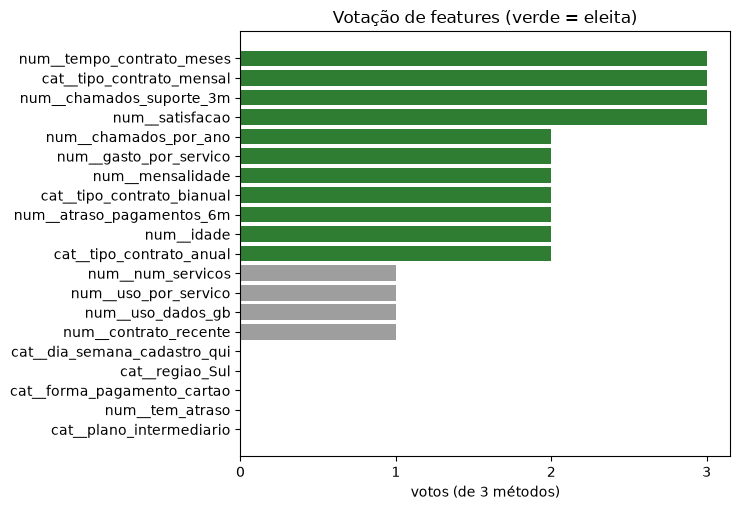

In [6]:
ev = ciclo.dir_evidencias(ctx); ev.mkdir(parents=True, exist_ok=True)
proc = dir_(cfg, "dir_processed")

tabela.to_csv(ev / "tabela_votos.csv", index=False)
estab.to_csv(ev / "estabilidade_votacao.csv", index=False)
gravar_json(proc / "features_eleitas.json", {"cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"],
                                              "regra": cfg["selecao_features"]["regra_votacao"], "features": eleitas})
gravar_json(proc / "votacao_folds.json", {"cycle_id": ctx["cycle_id"], "data_version": ctx["data_version"], "folds": votos_folds})
gravar_json(ev / "features_eleitas.json", {"cycle_id": ctx["cycle_id"], "features": eleitas})

graf = tabela.sort_values(["votos", "escore_medio_norm"]).tail(20)
plt.figure(figsize=(7.5, 5.2))
cores = np.where(graf["eleita"] == 1, "#2e7d32", "#9e9e9e")
plt.barh(graf["feature"], graf["votos"], color=cores)
plt.xticks([0, 1, 2, 3]); plt.xlabel("votos (de 3 métodos)")
plt.title("Votação de features (verde = eleita)"); plt.tight_layout()
plt.savefig(ev / "votacao_features.png", dpi=130); plt.show()

## Registro no MLflow

In [7]:
sf = cfg["selecao_features"]
rastreio.configurar(cfg)
with rastreio.run("votacao_features", ctx, etapa="votacao", tags_extra={"features_eleitas": ",".join(eleitas)}) as r:
    mlflow.log_params({"metodos": "+".join(ft.METODOS), "metodo_votacao": sf["regra_votacao"],
                       "k_por_metodo": sf["k_por_metodo"], "min_votos": sf["min_votos"],
                       "min_features": sf["min_features"], "max_features": sf["max_features"],
                       "rf_n_estimators": sf["rf_n_estimators"], "seed": cfg["projeto"]["seed"],
                       "n_candidatas": Xt.shape[1]})
    mlflow.log_metrics({"n_features_eleitas": len(eleitas), "jaccard_medio_folds": float(np.mean(jacc))})
    for arq in ("tabela_votos.csv", "estabilidade_votacao.csv", "features_eleitas.json", "votacao_features.png"):
        mlflow.log_artifact(str(ev / arq))
    mlflow.log_artifact(str(proc / "votacao_folds.json"))
    ctx["run_ids"]["votacao"] = r.info.run_id
ctx["features_eleitas"] = eleitas
ciclo.salvar_contexto(cfg, ctx)
print("Features eleitas:", eleitas)

Features eleitas: ['num__tempo_contrato_meses', 'cat__tipo_contrato_mensal', 'num__chamados_suporte_3m', 'num__satisfacao', 'num__chamados_por_ano', 'num__gasto_por_servico', 'num__mensalidade', 'cat__tipo_contrato_bianual', 'num__atraso_pagamentos_6m', 'num__idade', 'cat__tipo_contrato_anual']
